## Proyecto punta a punta

Cuántos terremotos habrá mañana en Tenerife


#### Forecasting:

## DATOS :

Un técnico en vulcanología quiere saber cuantos terremotos podrían generarse en el día de mañana en Tenerife para saber si es normal o es raro la cantidad.

Datos -> catálogo adquirido del IGN de los terremotos mayores a 1,0. En csv.

* 2 archivos -> desde 1981 hasta 2017, y de 2017 hasta hoy.

No predice erupciones que iba a ser el tema principal. La última fue Chinyero 1909. Solo predice el número de terremotos y veremos si la magnitud del mismo.

In [1]:
! pip install pandas numpy matplotlib seaborn joblib scikit-learn

  Using cached pandas-3.0.6-cp314-cp314-win_amd64.whl.metadata (19 kB)
  Using cached numpy-2.5.3-cp314-cp314-win_amd64.whl.metadata (6.6 kB)
  Using cached matplotlib-3.11.2-cp314-cp314-win_amd64.whl.metadata (80 kB)
  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached scikit_learn-1.9.1-cp314-cp314-win_amd64.whl.metadata (9.3 kB)
  Using cached contourpy-1.4.0-cp314-cp314-win_amd64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached fonttools-4.66.1-cp314-cp314-win_amd64.whl.metadata (132 kB)
  Using cached kiwisolver-1.5.1-cp314-cp314-win_amd64.whl.metadata (5.2 kB)
  Using cached pillow-12.3.0-cp314-cp314-win_amd64.whl.metadata (9.3 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
  Using cached scipy-1.18.1-cp314-cp314-win_amd64.whl.metadata (61 kB)
  Using

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error

In [12]:
# Los archivos del IGN vienen separados por ; y con espacios
# Después de descubrir por qué no se cargaban bien los datos, descubrí el qué era y lo busqué para solucionarlo. El problema era que los archivos del IGN vienen separados por ; y con espacios, lo que hacía que al leerlos con pandas, se generaran columnas vacías y no se cargaran correctamente los datos. 
# Para solucionarlo, se puede usar el parámetro sep=';' y skipinitialspace=True al leer el archivo con pandas.

df1 = pd.read_csv("../data/catalogo_ign_1981_2017.csv", sep=";", skipinitialspace=True)
df2 = pd.read_csv("../data/catalogo_ign_2017_2026.csv", sep=";", skipinitialspace=True)

print('df1:', df1.shape)
print('df2:', df2.shape)

df1.head()

df1: (25740, 10)
df2: (94004, 10)


,Evento,Fecha,Hora,Latitud,Longitud,Prof. (Km),Inten.,Mag.,Tipo Mag.,Localizaci�n
0,9044,22/04/1981,17:41:12,28.099,-16.174,5.0,V,3.8,13.0,"E San Miguel de Tajao.TF,Zona atlántica Teneri..."
1,9183,13/10/1981,05:28:24,28.013,-17.862,0.0,NaN,2.4,13.0,"N Isla de El Hierro,Oceáno Atlántico"
2,es1981vxaza,08/11/1981,10:55:27,29.122,-16.271,0.0,NaN,2.8,13.0,"N Isla de Tenerife,Oceáno Atlántico"
3,9202,16/11/1981,02:31:28,29.987,-15.375,5.0,NaN,3.8,13.0,"NE Isla de Tenerife,Oceáno Atlántico"
4,9322,25/04/1982,04:15:32,28.826,-16.477,5.0,NaN,2.7,13.0,"N Isla de Tenerife,Oceáno Atlántico"


In [ ]:
# Juntamos las 2 tablas en 1 sola

df = pd.concat([df1, df2], ignore_index=True)

# Los nombres de la columna traen espacios y algunos con caracteres raros así que solucionamos

df.columns = ["evento","fecha","hora","latitud","longitud","profundidad","intensidad","magnitud","tipo_mag","localizacion"]

filas_inicio = len(df)
print("Filas al inicio:", filas_inicio)
df.tail() # mostramos las últimas filas para ver si hay algo raro en los datos

Filas al inicio: 119744


,evento,fecha,hora,latitud,longitud,profundidad,intensidad,magnitud,tipo_mag,localizacion
119739,es2026toxro,06/10/2026,11:38:03,37.0712,-3.5997,4.0,NaN,1.8,4.0,SE DÍLAR.GR
119740,es2026tpabg,06/10/2026,12:48:43,42.9675,0.1724,0.0,NaN,2.1,4.0,NW LA MONGIE.FRA
119741,es2026tpbfq,06/10/2026,13:24:07,37.0123,-3.5731,4.0,NaN,1.6,4.0,NW DÚRCAL.GR
119742,es2026tpbqu,06/10/2026,13:37:07,37.0894,-3.5525,6.0,NaN,1.3,4.0,SE LA ZUBIA.GR
119743,es2026tpbqy,06/10/2026,13:37:17,37.1058,-3.5717,6.0,NaN,1.5,4.0,SE LA ZUBIA.GR


#### Las columnas que me interesan son: Fecha, longitud, latitud y magnitud.

## Revisamos nulos/duplicados

In [14]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 119744 entries, 0 to 119743
Data columns (total 10 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   evento        119744 non-null  str    
 1   fecha         119744 non-null  str    
 2   hora          119744 non-null  str    
 3   latitud       119744 non-null  float64
 4   longitud      119744 non-null  float64
 5   profundidad   119744 non-null  float64
 6   intensidad    7181 non-null    str    
 7   magnitud      119741 non-null  float64
 8   tipo_mag      119741 non-null  float64
 9   localizacion  119744 non-null  str    
dtypes: float64(5), str(5)
memory usage: 9.1 MB


In [15]:
# nulos

df.isnull().sum()

evento               0
fecha                0
hora                 0
latitud              0
longitud             0
profundidad          0
intensidad      112563
magnitud             3
tipo_mag             3
localizacion         0
dtype: int64

In [16]:
df = df.drop(columns=["intensidad", "tipo_mag"]) #eliminamos las columnas que no nos interesan
df = df.dropna(subset=["magnitud"]) #eliminamos las filas con valores nulos

filas_sin_nulos = len(df)
print("Sin nulos:", filas_sin_nulos)

Sin nulos: 119741


#### Vemos que pueden haber duplicados en los datos, ya que ambos archivos tienen el año 2017.

#### Procedemos a revisar y a eliminarlos

In [17]:
df["evento"] = df["evento"].astype(str).str.strip() # eliminamos los espacios en blanco al inicio y al final de la columna evento
print("Repetidos: ", df.duplicated(subset="evento").sum()) # contamos los duplicados en la columna evento

Repetidos:  720


#### Efectivamente hay 720 eventos repetidos

Los quitamos

In [18]:
df = df.drop_duplicates(subset="evento") # eliminamos los duplicados en la columna evento
filas_sin_duplicados = len(df)
print("Sin duplicados:", filas_sin_duplicados)


Sin duplicados: 119021


#### Cambiamos el formato de la fecha de texto a datetime

In [19]:
df["fecha"] = pd.to_datetime(df["fecha"], format="%d/%m/%Y") #convertimos la columna fecha a tipo datetime
print("Primera fecha:", df["fecha"].min())
print("Última fecha:", df["fecha"].max())

Primera fecha: 1981-04-22 00:00:00
Última fecha: 2026-10-06 00:00:00


In [20]:
# Valores imposibles: miro mínimos y máximos
df[["latitud", "longitud", "profundidad", "magnitud"]].describe()

,latitud,longitud,profundidad,magnitud
count,119021.000000,119021.000000,119021.000000,119021.000000
mean,33.624563,-9.946617,11.811322,1.762271
std,5.488251,7.358016,10.478623,0.734576
min,26.245500,-19.974300,0.000000,-2.000000
25%,28.141400,-17.841300,4.000000,1.300000
50%,35.452200,-8.536900,11.000000,1.700000
75%,37.238600,-3.597200,16.000000,2.200000
max,44.985000,5.996600,126.800000,6.800000


Vemos que la mayoría de los terremotos están dentro de españa. Hay valores negativos y preguntando a la IA, me dice que al ser pequeño puede ser negativo.
Hay muchos valores de profundidad, pero como no lo vamos a usar, pues se queda tranquilita.
La ultima fecha y hora del ultimo terremoto es del 6 de octubre de 2026, por lo que lo eliminamos al no completarlo. 

In [22]:
df = df[df["fecha"] <= "2026-10-05"]

filas_limpias = len(df)
print("Filas después de quitar el día incompleto:", filas_limpias)

Filas después de quitar el día incompleto: 118999


#### Como queremos trabajar con Tenerife y alrededores (Gran Canaria), dibujamos un rectangulo para no salirnos de la isla 

In [23]:
tf = df[(df["latitud"] >= 27.9) & (df["latitud"] <= 28.7) &
        (df["longitud"] >= -17.0) & (df["longitud"] <= -16.0)].copy()

print("Terremotos en el rectángulo de Tenerife (1981-2026):", len(tf))

Terremotos en el rectángulo de Tenerife (1981-2026): 15811


#### Con diagrama de puntos, vemos si ha cogido el rectángulo de Tenerife y "el volcán de el medio" (que está en el mar)

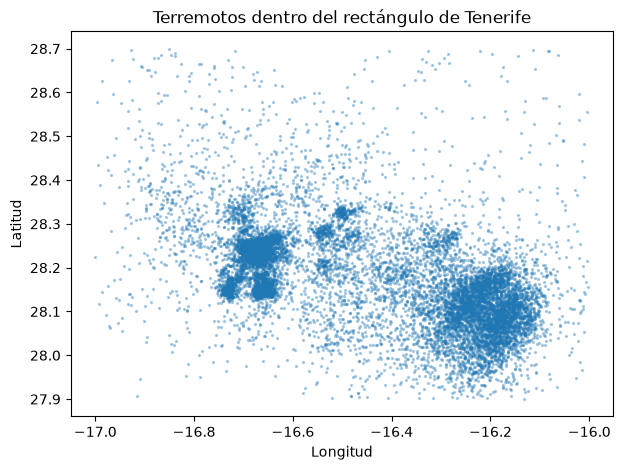

In [24]:
plt.figure(figsize=(7, 5))
plt.scatter(tf["longitud"], tf["latitud"], s=2, alpha=0.3)
plt.title("Terremotos dentro del rectángulo de Tenerife")
plt.xlabel("Longitud")
plt.ylabel("Latitud")
plt.show()

Efectivamente, ha cogido Tenerife y el "vocán de en medio" donde suele haber muchos terremotos

#### Vamos a ver cuántos terremotos al año han habido desde 2008 y la magnitud de los mismos

In [25]:
por_ano = tf.groupby(tf["fecha"].dt.year)["magnitud"].agg(["count", "median"])
por_ano.columns = ["terremotos", "magnitud_mediana"]
por_ano.loc[2008:]

,terremotos,magnitud_mediana
fecha,,
2008,79,1.60
2009,50,1.80
2010,57,1.60
2011,60,1.50
2012,72,1.70
2013,38,1.65
2014,100,1.55
2015,128,1.60
2016,256,1.10


##### La verdad que es un poco extraño la diferencia de terremotos del 2016 al 2017, donde empiezan a registrarse más.

##### Tomamos la decisión de eliminar los terremotos anteriores al 2017 para que no afecten al modelo y, como dijimos al principio, con magnitudes superiores a 1,0.

In [26]:
tf = tf[(tf["fecha"] >= "2017-01-01") & (tf["magnitud"] >= 1.0)].copy()

filas_final = len(tf)

print("Tenerife y entorno, desde 2017, magnitud >= 1:", filas_final)

Tenerife y entorno, desde 2017, magnitud >= 1: 8393


#### Para poder diferenciar que terremotos son de Tenerife y cuales son del volcan de en medio (mar), usamos las 2 localizaciones diferentes que nos ofrece IGN. Tenerife y Atlantico Canarias(mar)

In [27]:
tf["zona"] = np.where(tf["localizacion"].str.contains("ATLÁNTICO"), "mar", "isla")

print(tf["zona"].value_counts())
pd.crosstab(tf["fecha"].dt.year, tf["zona"])

zona
mar     4246
isla    4147
Name: count, dtype: int64


zona,isla,mar
fecha,,
2017,277,359
2018,455,485
2019,303,477
2020,252,454
2021,224,307
2022,345,334
2023,369,509
2024,298,503
2025,399,511


#### Iba a separar las 2 para entrenar el modelo con Tenerife, pero serían datos muy pobres y, aparte, la mitad de los días habrían 0 terremotos.

In [28]:
conteo = tf.groupby("fecha").size()

todos_los_dias = pd.date_range("2017-01-01", "2026-10-05")
conteo = conteo.reindex(todos_los_dias, fill_value=0)

serie = pd.DataFrame({"fecha": conteo.index, "terremotos": conteo.values})

print("Días en la serie:", len(serie))
print("Días sin terremotos:", (serie["terremotos"] == 0).sum())
serie["terremotos"].describe()

Días en la serie: 3565
Días sin terremotos: 673


count    3565.000000
mean        2.354278
std         4.310271
min         0.000000
25%         1.000000
50%         2.000000
75%         3.000000
max       139.000000
Name: terremotos, dtype: float64

#### Exceptuando cuando hay enjambres, en la mayoría de los días, suelen haber entre 2 y 3 terremotos

# EDA

##### Miramos los datos con gráficos para entender como es la variable que quiero predecir y cuales se relacionen con ella

### Gráfico 1

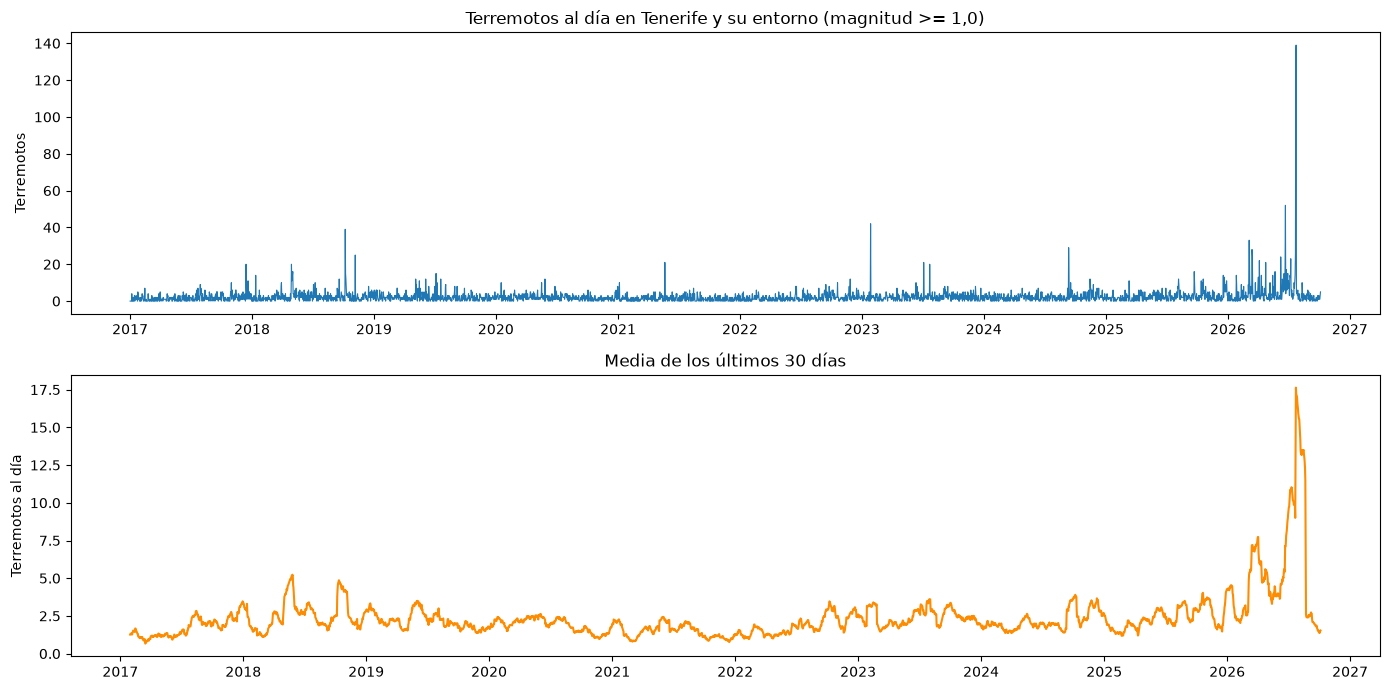

In [29]:
fig, ax = plt.subplots(2, 1, figsize=(14, 7))

ax[0].plot(serie["fecha"], serie["terremotos"], linewidth=0.8)
ax[0].set_title("Terremotos al día en Tenerife y su entorno (magnitud >= 1,0)")
ax[0].set_ylabel("Terremotos")

# Media de 30 días para ver mejor el nivel de fondo
ax[1].plot(serie["fecha"], serie["terremotos"].rolling(30).mean(), color="darkorange")
ax[1].set_title("Media de los últimos 30 días")
ax[1].set_ylabel("Terremotos al día")

plt.tight_layout()
plt.show()

In [33]:
# Vamos a ver con los 10 días con más terremotos

serie.sort_values("terremotos", ascending=False).head(10)

,fecha,terremotos
3491,2026-07-24,139
3490,2026-07-23,132
3459,2026-06-22,52
2217,2023-01-27,42
644,2018-10-07,39
3350,2026-03-05,33
3351,2026-03-06,33
2810,2024-09-11,29
3359,2026-03-14,28
3489,2026-07-22,26


### Gráfico 2

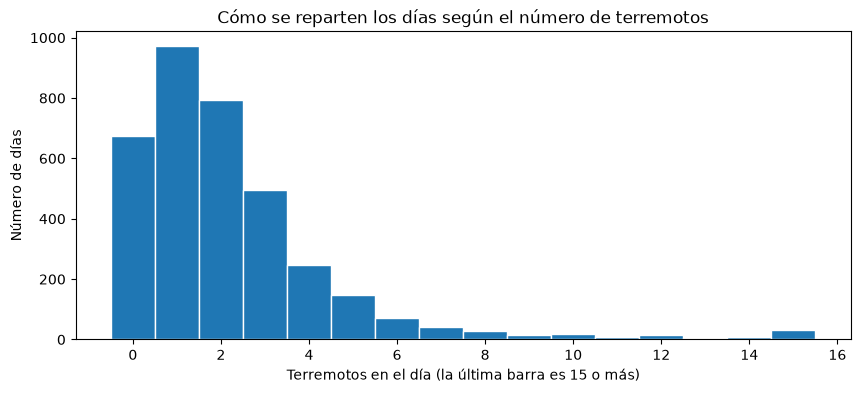

Días con 3 terremotos o menos: 82.3 %
Días con 10 terremotos o más:  2.3 %
Media: 2.35 | Mediana: 2.0


In [32]:
# Junto en la última barra todos los días con 15 terremotos o más, para que se vea bien
plt.figure(figsize=(10, 4))
plt.hist(serie["terremotos"].clip(upper=15), bins=range(0, 17), align="left", edgecolor="white")
plt.title("Cómo se reparten los días según el número de terremotos")
plt.xlabel("Terremotos en el día (la última barra es 15 o más)")
plt.ylabel("Número de días")
plt.show()

print("Días con 3 terremotos o menos:", round((serie["terremotos"] <= 3).mean() * 100, 1), "%")
print("Días con 10 terremotos o más: ", round((serie["terremotos"] >= 10).mean() * 100, 1), "%")
print("Media:", round(serie["terremotos"].mean(), 2), "| Mediana:", serie["terremotos"].median())

#### Vemos que la media está por encima de la mediana, ya que los días de enjambre, hace que suba. Esto es importante, ya que los modelos aprenderán sobre como es un día normal.

### Graffico 3:

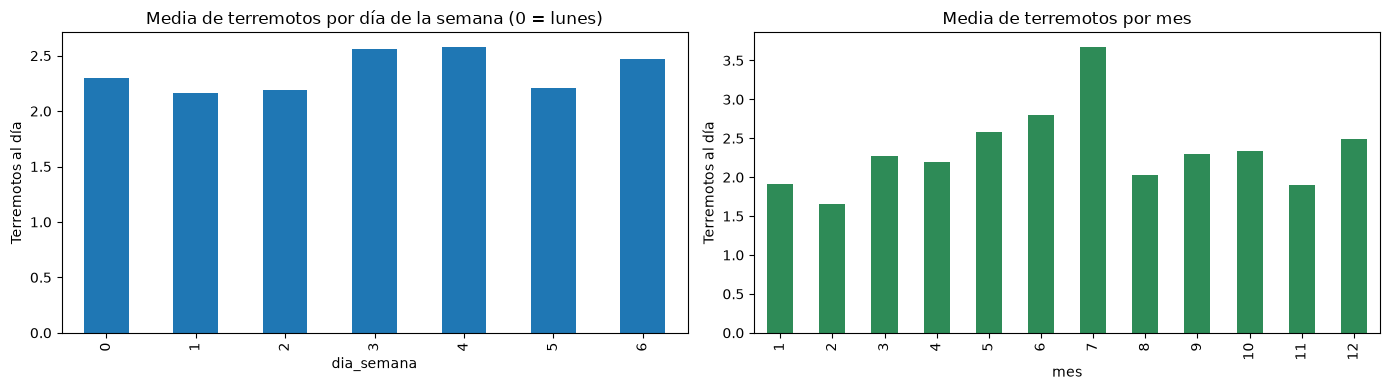

In [34]:
serie["dia_semana"] = serie["fecha"].dt.dayofweek
serie["mes"] = serie["fecha"].dt.month

fig, ax = plt.subplots(1, 2, figsize=(14, 4))

serie.groupby("dia_semana")["terremotos"].mean().plot(kind="bar", ax=ax[0])
ax[0].set_title("Media de terremotos por día de la semana (0 = lunes)")
ax[0].set_ylabel("Terremotos al día")

serie.groupby("mes")["terremotos"].mean().plot(kind="bar", ax=ax[1], color="seagreen")
ax[1].set_title("Media de terremotos por mes")
ax[1].set_ylabel("Terremotos al día")

plt.tight_layout()
plt.show()

El calendario no explica nada. Al volcán/terremotos, le da igual que día es...

### Gráfico 4

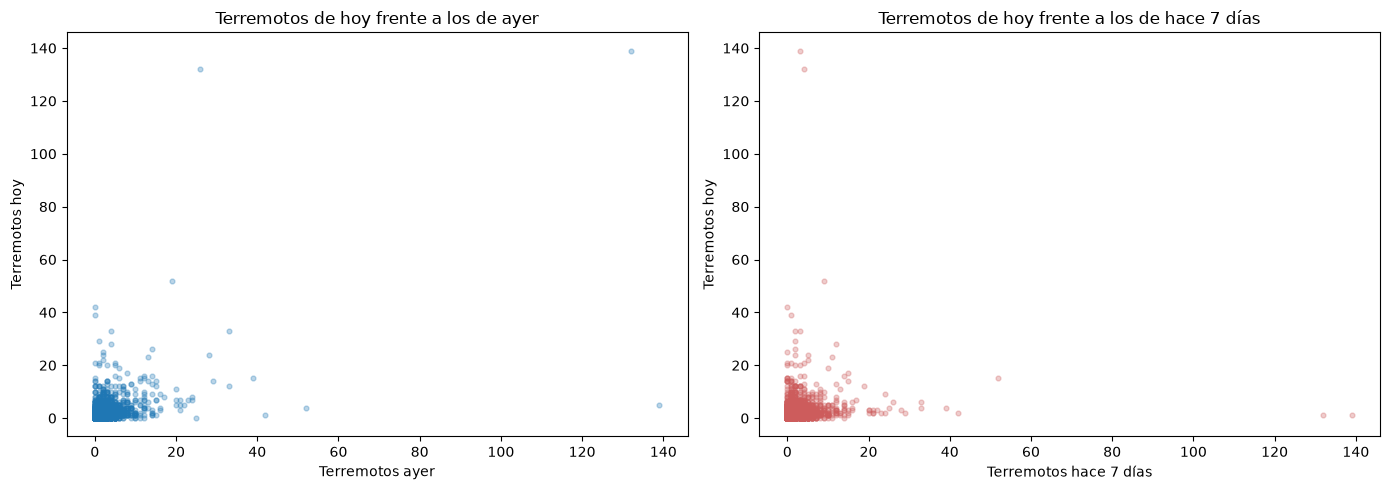

Correlación con ayer:        0.46
Correlación con hace 7 días: 0.07


In [35]:
serie["ayer"] = serie["terremotos"].shift(1)
serie["hace_7"] = serie["terremotos"].shift(7)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

ax[0].scatter(serie["ayer"], serie["terremotos"], alpha=0.3, s=12)
ax[0].set_title("Terremotos de hoy frente a los de ayer")
ax[0].set_xlabel("Terremotos ayer")
ax[0].set_ylabel("Terremotos hoy")

ax[1].scatter(serie["hace_7"], serie["terremotos"], alpha=0.3, s=12, color="indianred")
ax[1].set_title("Terremotos de hoy frente a los de hace 7 días")
ax[1].set_xlabel("Terremotos hace 7 días")
ax[1].set_ylabel("Terremotos hoy")

plt.tight_layout()
plt.show()

print("Correlación con ayer:       ", round(serie["terremotos"].corr(serie["ayer"]), 2))
print("Correlación con hace 7 días:", round(serie["terremotos"].corr(serie["hace_7"]), 2))

El baseline del forecasting (valor de 7 días) será flojito. Ayer 0.46 y hace 7 días 0,07.

### Gráfico 5

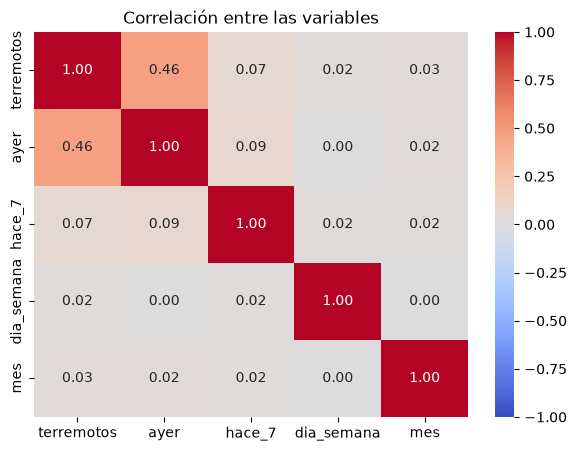

In [36]:
correlaciones = serie[["terremotos", "ayer", "hace_7", "dia_semana", "mes"]].corr()

plt.figure(figsize=(7, 5))
sns.heatmap(correlaciones, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlación entre las variables")
plt.show()

El mapa resume lo de los gráficos anteriores. Mirando la primera fila (la de terremotos):

* ayer es la única variable con una relación clara (0,46).
* hace 7 días casi nada (0,07).
* día y mes prácticamente cero (0,02 y 0,03).

### Gráfico 6

Comparamos una erupción de verdad (Hierro 2011) con Tenerife

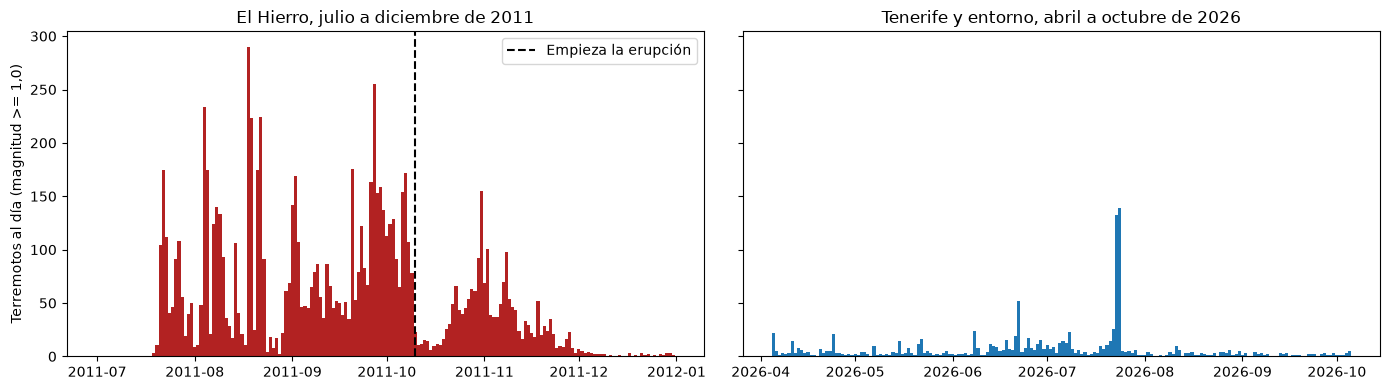

El Hierro: terremotos entre el 1 de julio y el 9 de octubre de 2011: 7117
Tenerife y entorno: terremotos entre el 5 de abril y el 5 de octubre de 2026: 1140


In [37]:
hierro = df[(df["latitud"] >= 27.4) & (df["latitud"] <= 28.0) &
            (df["longitud"] >= -18.5) & (df["longitud"] <= -17.7) &
            (df["magnitud"] >= 1.0)]

dias_hierro = pd.date_range("2011-07-01", "2011-12-31")
serie_hierro = hierro.groupby("fecha").size().reindex(dias_hierro, fill_value=0)

tenerife_2026 = serie[serie["fecha"] >= "2026-04-05"]

fig, ax = plt.subplots(1, 2, figsize=(14, 4), sharey=True)

ax[0].bar(serie_hierro.index, serie_hierro.values, width=1, color="firebrick")
ax[0].axvline(pd.Timestamp("2011-10-10"), color="black", linestyle="--", label="Empieza la erupción")
ax[0].set_title("El Hierro, julio a diciembre de 2011")
ax[0].set_ylabel("Terremotos al día (magnitud >= 1,0)")
ax[0].legend()

ax[1].bar(tenerife_2026["fecha"], tenerife_2026["terremotos"], width=1)
ax[1].set_title("Tenerife y entorno, abril a octubre de 2026")

plt.tight_layout()
plt.show()

print("El Hierro: terremotos entre el 1 de julio y el 9 de octubre de 2011:", serie_hierro[:"2011-10-09"].sum())
print("Tenerife y entorno: terremotos entre el 5 de abril y el 5 de octubre de 2026:", tenerife_2026["terremotos"].sum())

#### Resumen

* La variable objetivo está fatal repartida.
* El calendario ni se relaciona con el numero de terremotos
* Lo de ayer con lo de hace 7 días hará que el baseline sea flojo
* Queda mucho para que en tenerife haya un terremoto si tiene que igualar a la isla de El Hierro